# 04 · Modelos

1. separar as casas de treino (80%) e de teste (20%);
2. preparar os dados dentro do modelo;
3. comparar três modelos com validação cruzada;
4. treinar e gravar.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

DADOS = Path("..") / "data"
df = pd.read_csv(DADOS / "processed" / "dados_modelo.csv")

## 1. Treino e teste

- X: as variáveis que o modelo usa (tudo menos o preço e a área original).
- y: o que queremos prever, o preço.

O teste (20%) fica guardado até ao notebook 05 e não é usado para escolher nada. Assim mede o erro em casas que o modelo nunca viu.

In [2]:
X = df.drop(columns=["preco", "area_m2"])
y = df["preco"]

# random_state fixa a "sorte" da divisão, para dar sempre o mesmo resultado
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Treino: {len(X_treino)} casas | Teste: {len(X_teste)} casas")

df.loc[X_treino.index].to_csv(DADOS / "processed" / "treino.csv", index=False)
df.loc[X_teste.index].to_csv(DADOS / "processed" / "teste.csv", index=False)

Treino: 1242 casas | Teste: 311 casas


## 2. Preparar os dados dentro do modelo

Antes de treinar falta:

- preencher os valores em falta: a mediana nas colunas numéricas (o andar) e o valor mais frequente nas de texto (o estado);
- passar o texto (freguesia, estado, tipo) a colunas de 0 e 1 (one-hot encoding).

Estes passos ficam dentro do modelo, numa pipeline. Assim a mediana é aprendida só com as casas de treino, e as casas novas são preparadas da mesma forma.

O `TransformedTargetRegressor` aplica o logaritmo ao preço antes de treinar e desfaz o logaritmo (`np.exp`) quando prevê. O modelo aprende em log, mas responde em euros.

In [3]:
texto = ["freguesia", "estado", "tipo"]
numericas = [coluna for coluna in X.columns if coluna not in texto]

preparacao = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("texto", make_pipeline(SimpleImputer(strategy="most_frequent"),
                            OneHotEncoder(handle_unknown="ignore")), texto),
])

def criar_modelo(algoritmo):
    '''Junta a preparação, o algoritmo e o logaritmo do preço num só modelo.'''
    return TransformedTargetRegressor(regressor=make_pipeline(preparacao, algoritmo),
                                      func=np.log, inverse_func=np.exp)

## 3. Três modelos

| Modelo | Como funciona |
|---|---|
| Regressão Linear Múltipla | Uma equação: cada variável tem um peso, e o preço é a soma. Simples e fácil de ler. |
| Random Forest | Muitas árvores de decisão (300), cada uma treinada com uma amostra diferente das casas. A previsão é a média delas. |
| XGBoost | Gradient Boosting: árvores feitas em sequência, cada uma a corrigir os erros das anteriores. O XGBoost é a versão mais usada deste método e costuma ser dos melhores em dados em tabela. |

No XGBoost usamos valores habituais para aprender com cuidado: muitas árvores pequenas, cada uma a corrigir só um pouco, e cada resposta baseada em pelo menos 20 casas. Com as definições de origem, decorava demasiado as casas de treino: errava cerca de 1% no treino e 15% na validação.

In [4]:
modelos = {
    "Regressão Linear Múltipla": criar_modelo(LinearRegression()),
    "Random Forest": criar_modelo(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
    # 500 árvores (n_estimators); cada uma corrige só 5% do erro (learning_rate);
    # no máximo 4 perguntas seguidas (max_depth); cada resposta final vem de pelo menos 20 casas (min_child_weight)
    "XGBoost": criar_modelo(XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                                         min_child_weight=20, random_state=42, n_jobs=-1)),
}

### Comparar com validação cruzada

Para escolher, não usamos o teste. Usamos a validação cruzada nas casas de treino: dividimos o treino em 5 grupos, treinamos com 4 e medimos o erro no grupo que ficou de fora (a validação). Repetimos 5 vezes, com um grupo diferente de fora em cada volta. A média dos 5 erros diz qual modelo é melhor.

```
treino (1 242 casas) em 5 grupos:
volta 1: aprende com 2, 3, 4, 5 → erro no grupo 1
volta 2: aprende com 1, 3, 4, 5 → erro no grupo 2
...
volta 5: aprende com 1, 2, 3, 4 → erro no grupo 5
teste (311 casas): fica fechado, não entra em nenhuma volta
```

Porquê só no treino? A validação cruzada serve para escolher o modelo. Se as casas de teste entrassem nas voltas, também teriam sido usadas para escolher, e o erro medido no teste (notebook 05) ficava otimista. Assim: a validação cruzada escolhe, o teste mede.

Medimos o erro em percentagem do preço (MAPE, erro percentual médio): errar 50 mil € numa casa de 300 mil € é muito pior do que numa casa de 2 milhões.

Medimos também o erro no treino, nas casas com que o modelo aprendeu em cada volta. Se for muito mais baixo do que o erro na validação, o modelo decorou as casas de treino em vez de aprender o padrão geral: chama-se overfitting.

In [5]:
cinco_grupos = KFold(n_splits=5, shuffle=True, random_state=42)

linhas = []
for nome, modelo in modelos.items():
    # return_train_score=True: mede também o erro nas casas de treino de cada volta
    resultado = cross_validate(modelo, X_treino, y_treino, cv=cinco_grupos,
                               scoring="neg_mean_absolute_percentage_error", return_train_score=True)
    # o scikit-learn devolve o erro com sinal negativo (maior = melhor); o - volta a pô-lo positivo
    linhas.append({"modelo": nome,
                   "erro % no treino": -resultado["train_score"].mean() * 100,   # * 100 para ficar em %
                   "erro % na validação": -resultado["test_score"].mean() * 100})

erros = pd.DataFrame(linhas).set_index("modelo").sort_values("erro % na validação")
erros.round(1)

,erro % no treino,erro % na validação
modelo,,
XGBoost,8.4,14.5
Random Forest,5.4,14.9
Regressão Linear Múltipla,15.0,15.9


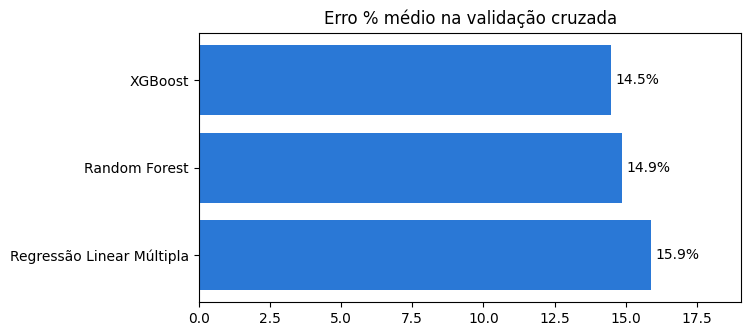

In [6]:
validacao = erros["erro % na validação"]

fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.barh(validacao.index, validacao.values, color="#2a78d6")
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.invert_yaxis()   # o melhor fica em cima
ax.set_title("Erro % médio na validação cruzada")
ax.set_xlim(0, validacao.max() * 1.2)
plt.show()

O que vemos:

- O XGBoost tem o menor erro na validação (14,5%), seguido do Random Forest (14,9%) e da regressão linear múltipla (15,9%).
- Os dois modelos de árvores ganham à regressão linear múltipla, porque apanham relações que não são retas (por exemplo, o valor de um m² depende da zona).
- Os modelos de árvores erram bem menos no treino (5% a 8%) do que na validação (cerca de 15%): decoram em parte as casas de treino. É normal nestes modelos; para escolher, o que conta é o erro na validação.
- A diferença entre os dois primeiros é pequena, mas a regra é escolher o de menor erro na validação cruzada: fica o XGBoost.

## 4. Treinar e gravar

Treinamos os três modelos com todas as casas de treino e gravamos tudo, com o nome do escolhido, para o notebook 05.

In [7]:
for modelo in modelos.values():
    modelo.fit(X_treino, y_treino)

escolhido = erros.index[0]   # o de menor erro na validação cruzada
(Path("..") / "models").mkdir(exist_ok=True)
joblib.dump({"modelos": modelos, "escolhido": escolhido}, Path("..") / "models" / "modelos.joblib")
print(f"Modelo escolhido: {escolhido}")

Modelo escolhido: XGBoost
